In [2]:
import pandas as pd
from pathlib import Path

# --- paths ---
base_csv = Path(
    r"C:\Users\jbros\OneDrive\Documents\Bross_279_Match_Test\Bross_279_unique_sites_with_trees.csv"
)

out_csv = base_csv.with_name("Bross_279_site_summary.csv")

# --- load base table ---
df = pd.read_csv(base_csv, dtype={"site_id": str})

# expected columns in this file (from your sample):
# ['site_id', 'distance_to_coast_km', 'ecoregion_l3', 'climate_zone',
#  'bcz_native', 'elev_mean_m', 'slope_mean_deg', 'aspect_mean_deg', 'trees_per_ha']

# --- rename to match your desired names ---
rename_map = {
    "distance_to_coast_km": "distance_to_coast",
    "bcz_native": "bcz_code",
    "elev_mean_m": "elev_mean",
}
df = df.rename(columns=rename_map)

# if climate_zone were missing, we could derive it from bcz_code here;
# but your file already has climate_zone, so we just use it

# --- select only the columns you want ---
wanted_cols = [
    "site_id",
    "distance_to_coast",
    "climate_zone",
    "bcz_code",
    "elev_mean",
    "trees_per_ha",
]

missing = [c for c in wanted_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing expected columns in {base_csv.name}: {missing}")

final = (
    df[wanted_cols]
    .drop_duplicates(subset="site_id")
    .sort_values("site_id")
    .reset_index(drop=True)
)

# --- save result ---
final.to_csv(out_csv, index=False)

print(f"✓ Saved final summary table to:\n{out_csv}")
print(final.head())


✓ Saved final summary table to:
C:\Users\jbros\OneDrive\Documents\Bross_279_Match_Test\Bross_279_site_summary.csv
  site_id  distance_to_coast    climate_zone  bcz_code  elev_mean  \
0     130             32.807  coastal_inland        10     199.55   
1     131              9.489         coastal         7      75.61   
2     133             21.785         coastal         7     150.36   
3     147             22.127  coastal_inland        10     183.46   
4  AAD004             46.333  coastal_inland        10     633.25   

   trees_per_ha  
0      2.425631  
1     12.570762  
2      2.831146  
3     11.159819  
4    106.917226  


In [3]:
import pandas as pd
from pathlib import Path

summary_path = Path(
    r"C:\Users\jbros\OneDrive\Documents\Bross_279_Match_Test\Bross_279_site_summary.csv"
)

df = pd.read_csv(summary_path, dtype={"site_id": str})

# drop AUK002
df = df[df["site_id"] != "AUK002"].reset_index(drop=True)

df.to_csv(summary_path, index=False)

print(f"Rows after removing AUK002: {len(df)}")
print(df.head())


Rows after removing AUK002: 1523
  site_id  distance_to_coast    climate_zone  bcz_code  elev_mean  \
0     130             32.807  coastal_inland        10     199.55   
1     131              9.489         coastal         7      75.61   
2     133             21.785         coastal         7     150.36   
3     147             22.127  coastal_inland        10     183.46   
4  AAD004             46.333  coastal_inland        10     633.25   

   trees_per_ha  
0      2.425631  
1     12.570762  
2      2.831146  
3     11.159819  
4    106.917226  


In [4]:
import numpy as np
import pandas as pd
import geopandas as gpd
from pathlib import Path

# --- paths ---
PARCELS_PATH = Path(
    r"C:\Users\jbros\OneDrive\Documents\Bross_279_Match_Test\Agricultural_Commodity_2020_shapefile\farm_parcels_merged.shp"
)
SUMMARY_CSV = Path(
    r"C:\Users\jbros\OneDrive\Documents\Bross_279_Match_Test\Bross_279_site_summary.csv"
)
OUT_CSV = SUMMARY_CSV.with_name("Bross_279_nn_matches_top10_bottom30.csv")

CA_ALBERS_EPSG = 3310  # meters

# --- quantile settings ---
TOP_Q = 0.90      # top 10% = high density
LOW_POOL_Q = 0.30 # bottom 30% = low-density pool


def find_site_id_col(df):
    candidates = ["site_id", "SITE_ID", "Site_ID", "siteid", "permit_num", "objectid", "OBJECTID"]
    for c in candidates:
        if c in df.columns:
            return c
    df["site_id"] = df.index.astype(str)
    return "site_id"


def main():
    # load parcels + summary
    parcels = gpd.read_file(PARCELS_PATH)
    site_col = find_site_id_col(parcels)
    parcels = parcels.rename(columns={site_col: "site_id"})
    parcels["site_id"] = parcels["site_id"].astype(str)

    summary = pd.read_csv(SUMMARY_CSV, dtype={"site_id": str})

    if "trees_per_ha" not in summary.columns:
        raise ValueError(f"'trees_per_ha' not in {SUMMARY_CSV.name}. Columns: {list(summary.columns)}")

    # merge geometry + attributes
    gdf = parcels[["site_id", "geometry"]].merge(summary, on="site_id", how="inner")

    # keep only rows with valid tree density
    gdf = gdf.dropna(subset=["trees_per_ha"]).copy()

    # project to metric CRS for distance in meters
    gdf = gdf.to_crs(CA_ALBERS_EPSG)

    # centroids for distance calcs
    gdf["centroid"] = gdf.geometry.centroid

    # define high-density and low-density sets
    q_high = gdf["trees_per_ha"].quantile(TOP_Q)
    q_low = gdf["trees_per_ha"].quantile(LOW_POOL_Q)

    high = gdf[gdf["trees_per_ha"] >= q_high].copy()
    low_pool = gdf[gdf["trees_per_ha"] <= q_low].copy()

    if high.empty or low_pool.empty:
        raise ValueError(f"No parcels in high ({TOP_Q}) or low ({LOW_POOL_Q}) quantile groups.")

    print(f"High-density sites: {len(high)} (trees_per_ha >= {q_high:.2f})")
    print(f"Low-density pool:  {len(low_pool)} (trees_per_ha <= {q_low:.2f})")

    # build coordinate arrays (meters)
    high_xy = np.array([[pt.x, pt.y] for pt in high["centroid"]])
    low_xy = np.array([[pt.x, pt.y] for pt in low_pool["centroid"]])

    # compute distance matrix (high x low) in meters
    # if you have many parcels this is still fine for a few thousands
    diff = high_xy[:, None, :] - low_xy[None, :, :]
    dist_m = np.sqrt((diff ** 2).sum(axis=2))  # shape (n_high, n_low)

    # nearest low neighbor index for each high
    nn_idx = dist_m.argmin(axis=1)
    nn_dist_m = dist_m[np.arange(len(high)), nn_idx]

    # build result table
    matches = pd.DataFrame({
        "site_id_high": high["site_id"].values,
        "trees_per_ha_high": high["trees_per_ha"].values,
        "site_id_low": low_pool["site_id"].values[nn_idx],
        "trees_per_ha_low": low_pool["trees_per_ha"].values[nn_idx],
        "distance_km": nn_dist_m / 1000.0
    })

    matches["trees_diff"] = matches["trees_per_ha_high"] - matches["trees_per_ha_low"]

    # optional: sort by distance or by tree contrast
    matches = matches.sort_values(["distance_km"]).reset_index(drop=True)

    # save
    matches.to_csv(OUT_CSV, index=False)
    print(f"\n✓ Saved nearest-neighbor matches to:\n{OUT_CSV}")
    print(matches.head())


if __name__ == "__main__":
    main()


High-density sites: 1434 (trees_per_ha >= 233.39)
Low-density pool:  4256 (trees_per_ha <= 71.09)

✓ Saved nearest-neighbor matches to:
C:\Users\jbros\OneDrive\Documents\Bross_279_Match_Test\Bross_279_nn_matches_top10_bottom30.csv
  site_id_high  trees_per_ha_high site_id_low  trees_per_ha_low  distance_km  \
0       BVI186         254.532151      BVE100          4.918108     0.095265   
1       BVI186         254.532151      BVE100          4.918108     0.095265   
2       BVI186         254.532151      BVE100          4.918108     0.095265   
3       BVI186         254.532151      BVE100          4.918108     0.095265   
4       BVI186         254.532151      BVE100          4.918108     0.095265   

   trees_diff  
0  249.614043  
1  249.614043  
2  249.614043  
3  249.614043  
4  249.614043  


In [5]:
import numpy as np
import pandas as pd
import geopandas as gpd
from pathlib import Path

# --- paths ---
PARCELS_PATH = Path(
    r"C:\Users\jbros\OneDrive\Documents\Bross_279_Match_Test\Agricultural_Commodity_2020_shapefile\farm_parcels_merged.shp"
)
SUMMARY_CSV = Path(
    r"C:\Users\jbros\OneDrive\Documents\Bross_279_Match_Test\Bross_279_site_summary.csv"
)
OUT_CSV = SUMMARY_CSV.with_name("Bross_279_nn_matches_top10_bottom30.csv")

CA_ALBERS_EPSG = 3310  # meters

# --- quantile settings ---
TOP_Q = 0.90      # top 10% = high density
LOW_POOL_Q = 0.30 # bottom 30% = low-density pool


def find_site_id_col(df):
    candidates = ["site_id", "SITE_ID", "Site_ID", "siteid", "permit_num", "objectid", "OBJECTID"]
    for c in candidates:
        if c in df.columns:
            return c
    df["site_id"] = df.index.astype(str)
    return "site_id"


def main():
    # load parcels and make site_id explicit
    parcels = gpd.read_file(PARCELS_PATH)
    site_col = find_site_id_col(parcels)
    parcels = parcels.rename(columns={site_col: "site_id"})
    parcels["site_id"] = parcels["site_id"].astype(str)

    # dissolve to one geometry per site_id (this kills the repetition)
    parcels_unique = parcels[["site_id", "geometry"]].dissolve(by="site_id", as_index=False)

    # load summary (trees_per_ha etc.)
    summary = pd.read_csv(SUMMARY_CSV, dtype={"site_id": str})
    if "trees_per_ha" not in summary.columns:
        raise ValueError(f"'trees_per_ha' not in {SUMMARY_CSV.name}. Columns: {list(summary.columns)}")

    # merge geometry + attributes
    gdf = parcels_unique.merge(summary, on="site_id", how="inner")

    # keep only rows with valid tree density
    gdf = gdf.dropna(subset=["trees_per_ha"]).copy()

    # project to metric CRS for distance in meters
    gdf = gdf.to_crs(CA_ALBERS_EPSG)

    # centroids for distance calcs
    gdf["centroid"] = gdf.geometry.centroid

    # high-density and low-density sets
    q_high = gdf["trees_per_ha"].quantile(TOP_Q)
    q_low = gdf["trees_per_ha"].quantile(LOW_POOL_Q)

    high = gdf[gdf["trees_per_ha"] >= q_high].copy()
    low_pool = gdf[gdf["trees_per_ha"] <= q_low].copy()

    if high.empty or low_pool.empty:
        raise ValueError(f"No parcels in high ({TOP_Q}) or low ({LOW_POOL_Q}) quantile groups.")

    print(f"High-density sites: {len(high)} (trees_per_ha >= {q_high:.2f})")
    print(f"Low-density pool:  {len(low_pool)} (trees_per_ha <= {q_low:.2f})")

    # build coordinate arrays (meters)
    high_xy = np.array([[pt.x, pt.y] for pt in high["centroid"]])
    low_xy = np.array([[pt.x, pt.y] for pt in low_pool["centroid"]])

    # distance matrix high x low (meters)
    diff = high_xy[:, None, :] - low_xy[None, :, :]
    dist_m = np.sqrt((diff ** 2).sum(axis=2))

    # nearest low neighbor index for each high
    nn_idx = dist_m.argmin(axis=1)
    nn_dist_m = dist_m[np.arange(len(high)), nn_idx]

    # build result table
    matches = pd.DataFrame({
        "site_id_high": high["site_id"].values,
        "trees_per_ha_high": high["trees_per_ha"].values,
        "site_id_low": low_pool["site_id"].values[nn_idx],
        "trees_per_ha_low": low_pool["trees_per_ha"].values[nn_idx],
        "distance_km": nn_dist_m / 1000.0
    })

    matches["trees_diff"] = matches["trees_per_ha_high"] - matches["trees_per_ha_low"]

    # enforce uniqueness just in case
    matches = matches.drop_duplicates(
        subset=["site_id_high", "site_id_low"]
    ).reset_index(drop=True)

    # optional: sort by distance
    matches = matches.sort_values("distance_km").reset_index(drop=True)

    # save
    matches.to_csv(OUT_CSV, index=False)
    print(f"\n✓ Saved nearest-neighbor matches to:\n{OUT_CSV}")
    print(matches.head())


if __name__ == "__main__":
    main()


High-density sites: 153 (trees_per_ha >= 222.74)
Low-density pool:  457 (trees_per_ha <= 65.93)

✓ Saved nearest-neighbor matches to:
C:\Users\jbros\OneDrive\Documents\Bross_279_Match_Test\Bross_279_nn_matches_top10_bottom30.csv
  site_id_high  trees_per_ha_high site_id_low  trees_per_ha_low  distance_km  \
0       ASE020         229.592166      ASE011         13.394911     0.046183   
1       BVE038         226.414751      BVE094         48.520724     0.086287   
2       BVI186         254.532151      BVE100          4.918108     0.095265   
3       BVH027         264.908333      DJK001         48.326554     0.102849   
4       AWE478         224.433806      AWE329         24.450668     0.116208   

   trees_diff  
0  216.197254  
1  177.894027  
2  249.614043  
3  216.581779  
4  199.983138  


In [6]:
import numpy as np
import pandas as pd
import geopandas as gpd
from pathlib import Path

# --- paths ---
PARCELS_PATH = Path(
    r"C:\Users\jbros\OneDrive\Documents\Bross_279_Match_Test"
      r"\Agricultural_Commodity_2020_shapefile\farm_parcels_merged.shp"
)
SUMMARY_CSV = Path(
    r"C:\Users\jbros\OneDrive\Documents\Bross_279_Match_Test\Bross_279_site_summary.csv"
)

CA_ALBERS_EPSG = 3310  # meters


def find_site_id_col(df):
    candidates = ["site_id", "SITE_ID", "Site_ID", "siteid", "permit_num", "objectid", "OBJECTID"]
    for c in candidates:
        if c in df.columns:
            return c
    df["site_id"] = df.index.astype(str)
    return "site_id"


# 1) load + prep data once
parcels = gpd.read_file(PARCELS_PATH)
site_col = find_site_id_col(parcels)
parcels = parcels.rename(columns={site_col: "site_id"})
parcels["site_id"] = parcels["site_id"].astype(str)

# dissolve so each site_id has one geometry
parcels_unique = parcels[["site_id", "geometry"]].dissolve(by="site_id", as_index=False)

summary = pd.read_csv(SUMMARY_CSV, dtype={"site_id": str})
if "trees_per_ha" not in summary.columns:
    raise ValueError(f"'trees_per_ha' not in {SUMMARY_CSV.name}. Columns: {list(summary.columns)}")

gdf = parcels_unique.merge(summary, on="site_id", how="inner")
gdf = gdf.dropna(subset=["trees_per_ha"]).copy()

# project to metric CRS and compute centroids
gdf = gdf.to_crs(CA_ALBERS_EPSG)
gdf["centroid"] = gdf.geometry.centroid

print(f"Total unique sites in gdf: {len(gdf)}")


def match_for_params(gdf, top_q=0.9, low_q=0.3, w_dist=0.5, w_tree=0.5):
    """
    Match high-density sites to low-density sites.

    top_q  = quantile cutoff for high-density group (e.g. 0.9 = top 10%)
    low_q  = quantile cutoff for low-density pool (e.g. 0.3 = bottom 30%)
    w_dist = weight on distance in the score (0–1)
    w_tree = weight on |tree density difference| in the score (0–1)
    """

    q_high = gdf["trees_per_ha"].quantile(top_q)
    q_low = gdf["trees_per_ha"].quantile(low_q)

    high = gdf[gdf["trees_per_ha"] >= q_high].copy()
    low_pool = gdf[gdf["trees_per_ha"] <= q_low].copy()

    if high.empty or low_pool.empty:
        raise ValueError(f"No parcels in high ({top_q}) or low ({low_q}) quantile groups.")

    # coords and tree values
    high_xy = np.array([[pt.x, pt.y] for pt in high["centroid"]])
    low_xy = np.array([[pt.x, pt.y] for pt in low_pool["centroid"]])

    high_t = high["trees_per_ha"].to_numpy()
    low_t = low_pool["trees_per_ha"].to_numpy()

    # distance matrix (meters)
    diff_xy = high_xy[:, None, :] - low_xy[None, :, :]
    dist_m = np.sqrt((diff_xy ** 2).sum(axis=2))  # shape (n_high, n_low)

    # distance-only case (fast path)
    if w_tree == 0:
        nn_idx = dist_m.argmin(axis=1)
        nn_dist_m = dist_m[np.arange(len(high)), nn_idx]
    else:
        # matrix of |tree density differences|
        diff_t = np.abs(high_t[:, None] - low_t[None, :])

        # normalize both matrices so they are roughly 0–1
        # use 95th percentile to avoid huge outliers dominating
        dist_scale = np.nanpercentile(dist_m, 95)
        diff_scale = np.nanpercentile(diff_t, 95)
        dist_scale = dist_scale if dist_scale > 0 else 1.0
        diff_scale = diff_scale if diff_scale > 0 else 1.0

        dist_n = dist_m / dist_scale
        diff_n = diff_t / diff_scale

        # combined score
        score = w_dist * dist_n + w_tree * diff_n
        nn_idx = score.argmin(axis=1)
        nn_dist_m = dist_m[np.arange(len(high)), nn_idx]

    matches = pd.DataFrame({
        "site_id_high": high["site_id"].values,
        "trees_per_ha_high": high_t,
        "site_id_low": low_pool["site_id"].values[nn_idx],
        "trees_per_ha_low": low_t[nn_idx],
        "distance_km": nn_dist_m / 1000.0,
    })
    matches["trees_diff"] = matches["trees_per_ha_high"] - matches["trees_per_ha_low"]
    matches["abs_trees_diff"] = matches["trees_diff"].abs()

    # uniqueness safety
    matches = matches.drop_duplicates(["site_id_high", "site_id_low"]).reset_index(drop=True)

    summary = {
        "top_q": top_q,
        "low_q": low_q,
        "w_dist": w_dist,
        "w_tree": w_tree,
        "n_high": len(high),
        "n_low_pool": len(low_pool),
        "mean_dist_km": matches["distance_km"].mean(),
        "median_dist_km": matches["distance_km"].median(),
        "mean_abs_tree_diff": matches["abs_trees_diff"].mean(),
        "median_abs_tree_diff": matches["abs_trees_diff"].median(),
    }

    return matches, summary


# 2) run some tests to see trade-offs
results = []
param_grid = [
    # (top_q, low_q, w_dist, w_tree)
    (0.90, 0.30, 1.0, 0.0),  # pure distance, your original logic
    (0.90, 0.30, 0.5, 0.5),  # equal weight
    (0.90, 0.30, 0.3, 0.7),  # emphasize similarity in trees_per_ha
    (0.85, 0.30, 0.5, 0.5),  # widen high group
    (0.90, 0.20, 0.5, 0.5),  # narrow low pool
]

for top_q, low_q, w_d, w_t in param_grid:
    _, summ = match_for_params(gdf, top_q, low_q, w_dist=w_d, w_tree=w_t)
    results.append(summ)

summary_df = pd.DataFrame(results)
print(summary_df)


Total unique sites in gdf: 1523
   top_q  low_q  w_dist  w_tree  n_high  n_low_pool  mean_dist_km  \
0   0.90    0.3     1.0     0.0     153         457      0.852597   
1   0.90    0.3     0.5     0.5     153         457      2.402890   
2   0.90    0.3     0.3     0.7     153         457      3.299180   
3   0.85    0.3     0.5     0.5     229         457      2.485960   
4   0.90    0.2     0.5     0.5     153         305      1.853923   

   median_dist_km  mean_abs_tree_diff  median_abs_tree_diff  
0        0.689532          227.347353            225.808686  
1        2.176726          195.912170            187.204147  
2        2.732915          193.026689            183.922123  
3        2.142881          182.247145            175.432177  
4        1.520522          226.839108            219.911483  


In [7]:
# pick the recommended setting: top 10%, bottom 20%, balanced weights
matches, summ = match_for_params(
    gdf,
    top_q=0.90,
    low_q=0.20,
    w_dist=0.5,
    w_tree=0.5,
)

print(summ)

out_csv = SUMMARY_CSV.with_name("Bross_279_nn_matches_top10_bottom20_balanced.csv")
matches.to_csv(out_csv, index=False)
print(f"saved to: {out_csv}")
print(matches.head())


{'top_q': 0.9, 'low_q': 0.2, 'w_dist': 0.5, 'w_tree': 0.5, 'n_high': 153, 'n_low_pool': 305, 'mean_dist_km': np.float64(1.8539233072058836), 'median_dist_km': 1.5205221757934864, 'mean_abs_tree_diff': np.float64(226.8391081498039), 'median_abs_tree_diff': 219.91148293}
saved to: C:\Users\jbros\OneDrive\Documents\Bross_279_Match_Test\Bross_279_nn_matches_top10_bottom20_balanced.csv
  site_id_high  trees_per_ha_high site_id_low  trees_per_ha_low  distance_km  \
0       ACA003         244.132015      ACN003         25.319742     0.914600   
1       ACB252         247.092468      ACB506         33.019935     3.268985   
2       ACB505         223.918170      CHP004         33.215763     3.399294   
3       ACE106         250.149637      ACZ039         28.452360     1.348784   
4       ACE148         306.240447      AUU002         33.452841     1.314471   

   trees_diff  abs_trees_diff  
0  218.812273      218.812273  
1  214.072533      214.072533  
2  190.702406      190.702406  
3  221.

In [9]:
import numpy as np
import pandas as pd

def match_with_coast(
    gdf,
    top_q=0.90,
    low_q=0.20,
    w_xy=0.3,
    w_tree=0.2,
    w_coast=0.5,
    max_xy_dist_km=5.0,
    max_coast_diff_km=5.0,
):
    """
    Match high-density sites to low-density sites, optimizing:
      - centroid distance (small)
      - distance_to_coast difference (small)
      - trees_per_ha difference (large)

    All components are normalized to ~0–1 before weighting.
    """

    if "trees_per_ha" not in gdf.columns:
        raise ValueError("gdf needs a 'trees_per_ha' column.")
    if "distance_to_coast" not in gdf.columns:
        raise ValueError("gdf needs a 'distance_to_coast' column (in km).")
    if "centroid" not in gdf.columns:
        raise ValueError("gdf needs a 'centroid' geometry column.")

    # drop sites missing key vars
    g = gdf.dropna(subset=["trees_per_ha", "distance_to_coast"]).copy()

    # define high + low groups by quantiles
    q_high = g["trees_per_ha"].quantile(top_q)
    q_low = g["trees_per_ha"].quantile(low_q)

    high = g[g["trees_per_ha"] >= q_high].copy()
    low_pool = g[g["trees_per_ha"] <= q_low].copy()

    if high.empty or low_pool.empty:
        raise ValueError(f"No parcels in high ({top_q}) or low ({low_q}) quantile groups.")

    # coords (meters) and attributes
    high_xy = np.array([[pt.x, pt.y] for pt in high["centroid"]])
    low_xy = np.array([[pt.x, pt.y] for pt in low_pool["centroid"]])

    high_t = high["trees_per_ha"].to_numpy()
    low_t = low_pool["trees_per_ha"].to_numpy()

    high_c = high["distance_to_coast"].to_numpy()  # km
    low_c = low_pool["distance_to_coast"].to_numpy()

    # 1) centroid distance (meters → km)
    diff_xy = high_xy[:, None, :] - low_xy[None, :, :]
    dist_m = np.sqrt((diff_xy ** 2).sum(axis=2))
    dist_km = dist_m / 1000.0  # shape (n_high, n_low)

    # 2) trees_per_ha diff (absolute)
    diff_t = np.abs(high_t[:, None] - low_t[None, :])

    # 3) distance_to_coast diff (absolute, km)
    diff_coast = np.abs(high_c[:, None] - low_c[None, :])

    # normalize with robust 95th percentile scales
    def norm_matrix(mat):
        scale = np.nanpercentile(mat, 95)
        if not np.isfinite(scale) or scale == 0:
            scale = 1.0
        return mat / scale

    dist_n = norm_matrix(dist_km)
    diff_t_n = norm_matrix(diff_t)
    diff_coast_n = norm_matrix(diff_coast)

    # we want small dist_n, small diff_coast_n, large diff_t_n
    score = (
        w_xy * dist_n +
        w_coast * diff_coast_n -
        w_tree * diff_t_n    # minus because we want big tree contrast
    )

    # choose best low neighbor for each high
    nn_idx = score.argmin(axis=1)
    best_dist_km = dist_km[np.arange(len(high)), nn_idx]
    best_coast_diff_km = diff_coast[np.arange(len(high)), nn_idx]
    best_tree_diff = diff_t[np.arange(len(high)), nn_idx]

    matches = pd.DataFrame({
        "site_id_high": high["site_id"].values,
        "trees_per_ha_high": high_t,
        "distance_to_coast_high_km": high_c,
        "site_id_low": low_pool["site_id"].values[nn_idx],
        "trees_per_ha_low": low_t[nn_idx],
        "distance_to_coast_low_km": low_c[nn_idx],
        "distance_km": best_dist_km,
        "coast_diff_km": best_coast_diff_km,
        "abs_trees_diff": best_tree_diff,
    })

    # apply hard filters on distance + coast similarity
    matches = matches[
        (matches["distance_km"] <= max_xy_dist_km) &
        (matches["coast_diff_km"] <= max_coast_diff_km)
    ].copy()

    # ensure each high site appears once
    matches = matches.drop_duplicates(subset=["site_id_high"]).reset_index(drop=True)

    summary = {
        "top_q": top_q,
        "low_q": low_q,
        "w_xy": w_xy,
        "w_tree": w_tree,
        "w_coast": w_coast,
        "n_high": len(high),
        "n_low_pool": len(low_pool),
        "n_pairs_kept": len(matches),
        "mean_dist_km": matches["distance_km"].mean() if len(matches) else np.nan,
        "median_dist_km": matches["distance_km"].median() if len(matches) else np.nan,
        "mean_coast_diff_km": matches["coast_diff_km"].mean() if len(matches) else np.nan,
        "median_coast_diff_km": matches["coast_diff_km"].median() if len(matches) else np.nan,
        "mean_abs_tree_diff": matches["abs_trees_diff"].mean() if len(matches) else np.nan,
        "median_abs_tree_diff": matches["abs_trees_diff"].median() if len(matches) else np.nan,
    }

    return matches, summary


In [10]:
matches_opt, summ_opt = match_with_coast(
    gdf,
    top_q=0.90,
    low_q=0.20,
    w_xy=0.3,
    w_tree=0.2,
    w_coast=0.5,
    max_xy_dist_km=5.0,
    max_coast_diff_km=5.0,
)

print(summ_opt)

out_csv = SUMMARY_CSV.with_name("Bross_279_nn_matches_top10_bottom20_coast5km.csv")
matches_opt.to_csv(out_csv, index=False)
print("saved to:", out_csv)
matches_opt.head()


{'top_q': 0.9, 'low_q': 0.2, 'w_xy': 0.3, 'w_tree': 0.2, 'w_coast': 0.5, 'n_high': 153, 'n_low_pool': 305, 'n_pairs_kept': 145, 'mean_dist_km': np.float64(1.4681411560556705), 'median_dist_km': 1.0651689273120575, 'mean_coast_diff_km': np.float64(0.37917241379310357), 'median_coast_diff_km': 0.2519999999999989, 'mean_abs_tree_diff': np.float64(247.89369449282069), 'median_abs_tree_diff': 239.607655597}
saved to: C:\Users\jbros\OneDrive\Documents\Bross_279_Match_Test\Bross_279_nn_matches_top10_bottom20_coast5km.csv


,site_id_high,trees_per_ha_high,distance_to_coast_high_km,site_id_low,trees_per_ha_low,distance_to_coast_low_km,distance_km,coast_diff_km,abs_trees_diff
0,ACA003,244.132015,17.827,ACZ057,1.077330,17.054,1.365345,0.773,243.054685
1,ACB252,247.092468,17.453,ACA010,12.470218,17.943,0.729317,0.490,234.622250
2,ACB505,223.918170,17.509,ACA010,12.470218,17.943,1.957386,0.434,211.447952
3,ACE106,250.149637,15.188,ACH045,26.820308,15.510,1.144690,0.322,223.329329
4,ACE148,306.240447,16.080,ACE138,0.384936,16.591,0.417461,0.511,305.855512


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np

# paths
lst_path   = Path(r"C:\Users\jbros\OneDrive\Documents\SanDiego_RemoteSensing\OutputCSV\lst_means_all.csv")
match_path = Path(r"C:\Users\jbros\OneDrive\Documents\Bross_279_Match_Test\Bross_279_nn_matches_top10_bottom20_coast5km.csv")
out_dir = lst_path.parent  # save figs next to CSV

# 1) load wide LST table
lst_wide = pd.read_csv(lst_path, dtype={"site_id": str})

# all time columns
time_cols = [c for c in lst_wide.columns if c != "site_id"]

# parse timestamps
times = pd.to_datetime(time_cols, format="%Y.%m.%d.%H.%M.%S")

# filter June–September, 12:00–15:59, 2018–2024  (use .year/.month/.hour)
mask = (
    (times.year >= 2018) & (times.year <= 2024) &
    (times.month >= 6) & (times.month <= 9) &
    (times.hour >= 12) & (times.hour <= 15)
)
keep_cols = ["site_id"] + list(np.array(time_cols)[mask])

lst_sub = lst_wide[keep_cols].copy()

# reshape to long
lst_long = lst_sub.melt(id_vars="site_id", var_name="time_str", value_name="lst")
lst_long = lst_long.dropna(subset=["lst"])

lst_long["time"] = pd.to_datetime(lst_long["time_str"], format="%Y.%m.%d.%H.%M.%S")
lst_long["year"] = lst_long["time"].dt.year

# 2) load matched pairs
matches = pd.read_csv(match_path, dtype={"site_id_high": str, "site_id_low": str})
pairs = matches[["site_id_high", "site_id_low"]].copy()

years = range(2018, 2025)

for y in years:
    dy = lst_long[lst_long["year"] == y].copy()
    if dy.empty:
        continue

    present_sites = set(dy["site_id"])

    # only pairs where both sites have data in this year
    valid_pairs = pairs[
        pairs["site_id_high"].isin(present_sites) &
        pairs["site_id_low"].isin(present_sites)
    ].copy()
    if valid_pairs.empty:
        continue

    valid_ids = set(valid_pairs["site_id_high"]) | set(valid_pairs["site_id_low"])
    dy = dy[dy["site_id"].isin(valid_ids)].copy()
    if dy.empty:
        continue

    # map site -> group
    site_to_group = {}
    for row in valid_pairs.itertuples(index=False):
        site_to_group[row.site_id_high] = "High density"
        site_to_group[row.site_id_low] = "Low density"

    dy["group"] = dy["site_id"].map(site_to_group)
    dy = dy.dropna(subset=["group"])

    # average over all sites in each group at each time
    dplot = (
        dy.groupby(["time", "group"])["lst"]
          .mean()
          .reset_index()
          .sort_values("time")
    )
    if dplot.empty:
        continue

    # 3) plot (no interpolation, just lines through available dates)
    fig, ax = plt.subplots(figsize=(10, 4))
    for g, sub in dplot.groupby("group"):
        ax.plot(sub["time"], sub["lst"], label=g)

    ax.set_title(f"LST, June–September {y} (12:00–15:59)")
    ax.set_xlabel("time")
    ax.set_ylabel("lst")
    ax.legend(title="group")
    fig.tight_layout()

    out_fig = out_dir / f"lst_JunSep_{y}_pairs_mean.png"
    fig.savefig(out_fig, dpi=300)
    plt.close(fig)
    print("saved:", out_fig)


saved: C:\Users\jbros\OneDrive\Documents\SanDiego_RemoteSensing\OutputCSV\lst_JunSep_2018_pairs_mean.png
saved: C:\Users\jbros\OneDrive\Documents\SanDiego_RemoteSensing\OutputCSV\lst_JunSep_2019_pairs_mean.png
saved: C:\Users\jbros\OneDrive\Documents\SanDiego_RemoteSensing\OutputCSV\lst_JunSep_2020_pairs_mean.png
saved: C:\Users\jbros\OneDrive\Documents\SanDiego_RemoteSensing\OutputCSV\lst_JunSep_2021_pairs_mean.png
saved: C:\Users\jbros\OneDrive\Documents\SanDiego_RemoteSensing\OutputCSV\lst_JunSep_2022_pairs_mean.png
saved: C:\Users\jbros\OneDrive\Documents\SanDiego_RemoteSensing\OutputCSV\lst_JunSep_2023_pairs_mean.png
saved: C:\Users\jbros\OneDrive\Documents\SanDiego_RemoteSensing\OutputCSV\lst_JunSep_2024_pairs_mean.png


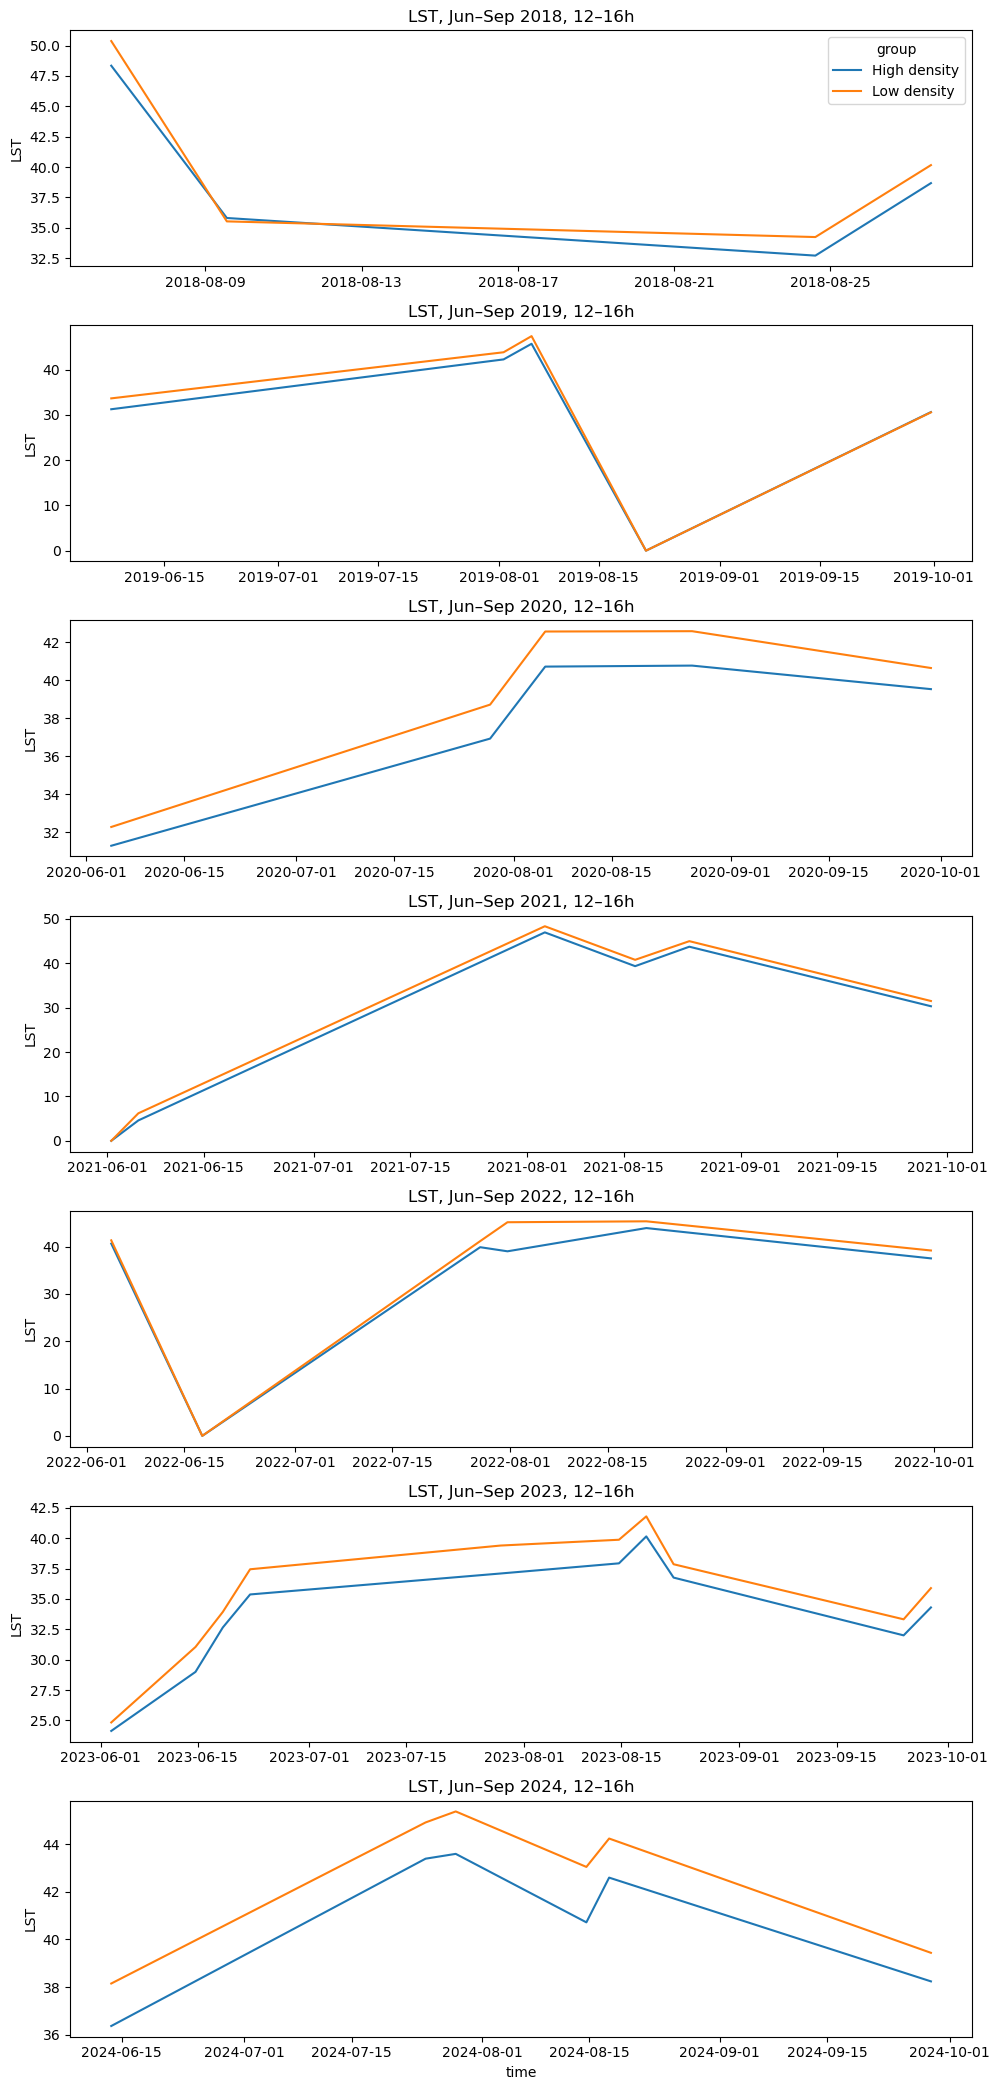

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np

# paths
lst_path   = Path(r"C:\Users\jbros\OneDrive\Documents\SanDiego_RemoteSensing\OutputCSV\lst_means_all.csv")
match_path = Path(r"C:\Users\jbros\OneDrive\Documents\Bross_279_Match_Test\Bross_279_nn_matches_top10_bottom20_coast5km.csv")

# 1) load wide LST table
lst_wide = pd.read_csv(lst_path, dtype={"site_id": str})

time_cols = [c for c in lst_wide.columns if c != "site_id"]
times = pd.to_datetime(time_cols, format="%Y.%m.%d.%H.%M.%S")

mask = (
    (times.year >= 2018) & (times.year <= 2024) &
    (times.month >= 6) & (times.month <= 9) &
    (times.hour >= 12) & (times.hour <= 15)
)
keep_cols = ["site_id"] + list(np.array(time_cols)[mask])
lst_sub = lst_wide[keep_cols].copy()

# wide -> long
lst_long = lst_sub.melt(id_vars="site_id", var_name="time_str", value_name="lst")
lst_long = lst_long.dropna(subset=["lst"])
lst_long["time"] = pd.to_datetime(lst_long["time_str"], format="%Y.%m.%d.%H.%M.%S")
lst_long["year"] = lst_long["time"].dt.year

# 2) matched pairs
matches = pd.read_csv(match_path, dtype={"site_id_high": str, "site_id_low": str})
pairs = matches[["site_id_high", "site_id_low"]].copy()

# 3) prep data per year first
year_series = {}
years = range(2018, 2025)

for y in years:
    dy = lst_long[lst_long["year"] == y].copy()
    if dy.empty:
        continue

    present_sites = set(dy["site_id"])
    valid_pairs = pairs[
        pairs["site_id_high"].isin(present_sites) &
        pairs["site_id_low"].isin(present_sites)
    ].copy()
    if valid_pairs.empty:
        continue

    valid_ids = set(valid_pairs["site_id_high"]) | set(valid_pairs["site_id_low"])
    dy = dy[dy["site_id"].isin(valid_ids)].copy()
    if dy.empty:
        continue

    site_to_group = {}
    for row in valid_pairs.itertuples(index=False):
        site_to_group[row.site_id_high] = "High density"
        site_to_group[row.site_id_low] = "Low density"

    dy["group"] = dy["site_id"].map(site_to_group)
    dy = dy.dropna(subset=["group"])

    dplot = (
        dy.groupby(["time", "group"])["lst"]
          .mean()
          .reset_index()
          .sort_values("time")
    )
    if dplot.empty:
        continue

    year_series[y] = dplot

if not year_series:
    print("no years with valid paired data")
else:
    # 4) single figure with subplots
    yrs = sorted(year_series.keys())
    n = len(yrs)
    fig, axes = plt.subplots(n, 1, figsize=(10, 3*n), sharex=False)

    if n == 1:
        axes = [axes]

    for ax, y in zip(axes, yrs):
        dplot = year_series[y]
        for g, sub in dplot.groupby("group"):
            ax.plot(sub["time"], sub["lst"], label=g)
        ax.set_title(f"LST, Jun–Sep {y}, 12–16h")
        ax.set_ylabel("LST")

        # simple legend only on top panel
        if y == yrs[0]:
            ax.legend(title="group")
        else:
            ax.legend_.remove() if ax.legend_ else None

    axes[-1].set_xlabel("time")
    fig.tight_layout()
    plt.show()


Used 145 pairs with ≥ 10 overlapping times.


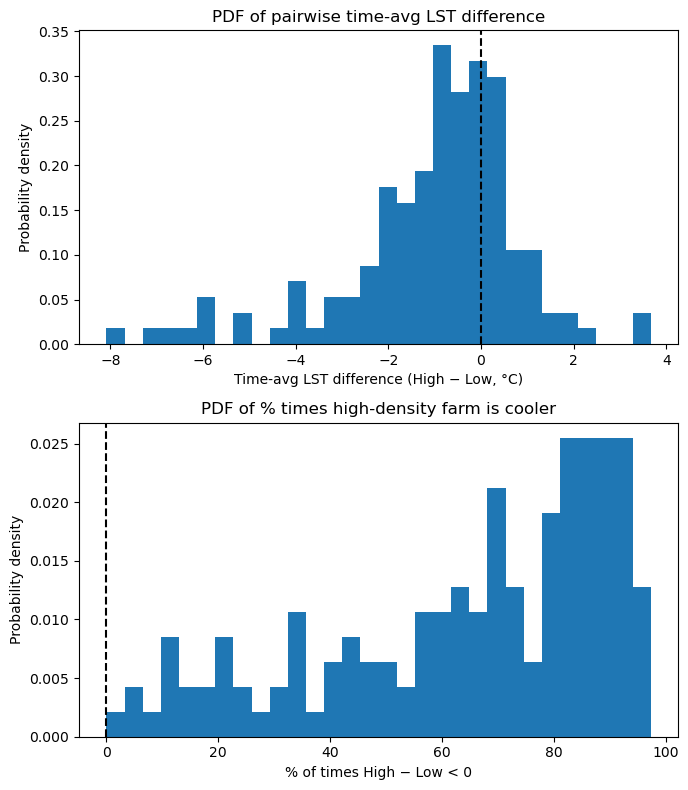

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# --- paths ---
lst_path = Path(
    r"C:\Users\jbros\OneDrive\Documents\SanDiego_RemoteSensing\OutputCSV\lst_means_all.csv"
)
match_path = Path(
    r"C:\Users\jbros\OneDrive\Documents\Bross_279_Match_Test\Bross_279_nn_matches_top10_bottom20_coast5km.csv"
)

# --- load wide LST table (site_id x time) ---
lst_wide = pd.read_csv(lst_path, dtype={"site_id": str})

time_cols = [c for c in lst_wide.columns if c != "site_id"]
times = pd.to_datetime(time_cols, format="%Y.%m.%d.%H.%M.%S")

# filter years 2018–2024, June–Sept, 12:00–15:59
mask = (
    (times.year >= 2018) & (times.year <= 2024) &
    (times.month >= 6) & (times.month <= 9) &
    (times.hour >= 12) & (times.hour <= 15)
)
sel_cols = list(np.array(time_cols)[mask])

lst_sub = lst_wide[["site_id"] + sel_cols].copy()
lst_sub = lst_sub.set_index("site_id")

# --- load matched pairs (high / low sites) ---
pairs = pd.read_csv(
    match_path,
    dtype={"site_id_high": str, "site_id_low": str}
)[["site_id_high", "site_id_low"]]

# --- compute per-pair stats ---
avg_diffs = []   # time-avg (High − Low)
neg_fracs = []   # % of times High − Low < 0
pair_labels = []

min_overlap = 10  # require at least 10 overlapping timestamps

for row in pairs.itertuples(index=False):
    hi = row.site_id_high
    lo = row.site_id_low

    if hi not in lst_sub.index or lo not in lst_sub.index:
        continue

    high_vals = lst_sub.loc[hi].to_numpy(dtype=float)
    low_vals  = lst_sub.loc[lo].to_numpy(dtype=float)

    valid = np.isfinite(high_vals) & np.isfinite(low_vals)
    if valid.sum() < min_overlap:
        continue

    diff = high_vals[valid] - low_vals[valid]

    avg_diffs.append(diff.mean())
    neg_fracs.append((diff < 0).mean() * 100.0)  # percent
    pair_labels.append(f"{hi}-{lo}")

avg_diffs = np.array(avg_diffs)
neg_fracs = np.array(neg_fracs)

print(f"Used {len(avg_diffs)} pairs with ≥ {min_overlap} overlapping times.")

# --- make figure with two PDFs ---
fig, axes = plt.subplots(2, 1, figsize=(7, 8))

# Top: PDF of time-averaged difference
axes[0].hist(avg_diffs, bins=30, density=True)
axes[0].axvline(0, color="k", linestyle="--")
axes[0].set_xlabel("Time-avg LST difference (High − Low, °C)")
axes[0].set_ylabel("Probability density")
axes[0].set_title("PDF of pairwise time-avg LST difference")

# Bottom: PDF of % times High − Low < 0
axes[1].hist(neg_fracs, bins=30, density=True)
axes[1].axvline(0, color="k", linestyle="--")
axes[1].set_xlabel("% of times High − Low < 0")
axes[1].set_ylabel("Probability density")
axes[1].set_title("PDF of % times high-density farm is cooler")

plt.tight_layout()
plt.show()


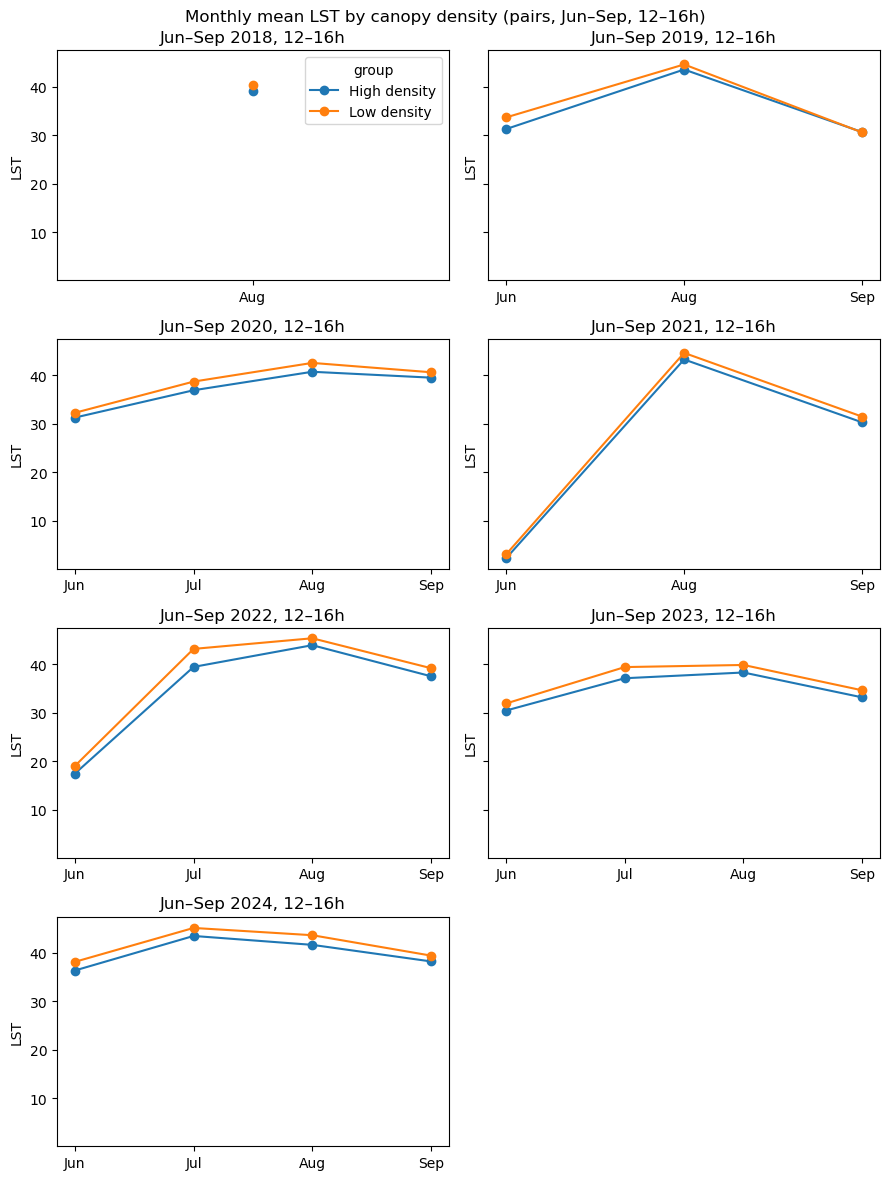

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np

# paths
lst_path   = Path(r"C:\Users\jbros\OneDrive\Documents\SanDiego_RemoteSensing\OutputCSV\lst_means_all.csv")
match_path = Path(r"C:\Users\jbros\OneDrive\Documents\Bross_279_Match_Test\Bross_279_nn_matches_top10_bottom20_coast5km.csv")

# 1) load wide LST table
lst_wide = pd.read_csv(lst_path, dtype={"site_id": str})

time_cols = [c for c in lst_wide.columns if c != "site_id"]
times = pd.to_datetime(time_cols, format="%Y.%m.%d.%H.%M.%S")

# Jun–Sep, 12–16h, 2018–2024
mask = (
    (times.year >= 2018) & (times.year <= 2024) &
    (times.month >= 6) & (times.month <= 9) &
    (times.hour >= 12) & (times.hour <= 15)
)
keep_cols = ["site_id"] + list(np.array(time_cols)[mask])
lst_sub = lst_wide[keep_cols].copy()

# wide -> long
lst_long = lst_sub.melt(id_vars="site_id", var_name="time_str", value_name="lst")
lst_long = lst_long.dropna(subset=["lst"])
lst_long["time"] = pd.to_datetime(lst_long["time_str"], format="%Y.%m.%d.%H.%M.%S")
lst_long["year"] = lst_long["time"].dt.year
lst_long["month"] = lst_long["time"].dt.month

# 2) matched pairs
matches = pd.read_csv(match_path, dtype={"site_id_high": str, "site_id_low": str})
pairs = matches[["site_id_high", "site_id_low"]].copy()

# 3) prep monthly mean LST (by year, month, group)
month_labels = {6: "Jun", 7: "Jul", 8: "Aug", 9: "Sep"}
per_year = {}
years = range(2018, 2025)

for y in years:
    dy = lst_long[lst_long["year"] == y].copy()
    if dy.empty:
        continue

    present_sites = set(dy["site_id"])
    valid_pairs = pairs[
        pairs["site_id_high"].isin(present_sites) &
        pairs["site_id_low"].isin(present_sites)
    ].copy()
    if valid_pairs.empty:
        continue

    valid_ids = set(valid_pairs["site_id_high"]) | set(valid_pairs["site_id_low"])
    dy = dy[dy["site_id"].isin(valid_ids)].copy()
    if dy.empty:
        continue

    # map sites to group
    site_to_group = {}
    for row in valid_pairs.itertuples(index=False):
        site_to_group[row.site_id_high] = "High density"
        site_to_group[row.site_id_low]  = "Low density"

    dy["group"] = dy["site_id"].map(site_to_group)
    dy = dy.dropna(subset=["group"])

    # monthly mean LST by group
    mmean = (
        dy.groupby(["month", "group"])["lst"]
          .mean()
          .reset_index()
    )

    wide = mmean.pivot(index="month", columns="group", values="lst")
    if wide.empty:
        continue

    # keep only months we care about + label
    wide = wide.sort_index()
    wide["month_label"] = wide.index.map(month_labels)
    per_year[y] = wide

# 4) plot: high vs low lines with dots, one panel per year
if not per_year:
    print("no years with valid paired data")
else:
    yrs = sorted(per_year.keys())
    n = len(yrs)
    ncols = 2
    nrows = (n + ncols - 1) // ncols

    fig, axes = plt.subplots(nrows, ncols, figsize=(9, 3*nrows), sharey=True)
    axes = axes.ravel()

    for ax, y in zip(axes, yrs):
        wide = per_year[y]
        x = wide["month_label"]

        if "High density" in wide.columns:
            ax.plot(x, wide["High density"], marker="o", label="High density")
        if "Low density" in wide.columns:
            ax.plot(x, wide["Low density"], marker="o", label="Low density")

        ax.set_title(f"Jun–Sep {y}, 12–16h")
        ax.set_ylabel("LST")

    # legend only on first axis
    axes[0].legend(title="group")

    # hide unused axes
    for j in range(len(yrs), len(axes)):
        fig.delaxes(axes[j])

    fig.suptitle("Monthly mean LST by canopy density (pairs, Jun–Sep, 12–16h)", y=0.98)
    fig.tight_layout()
    plt.show()


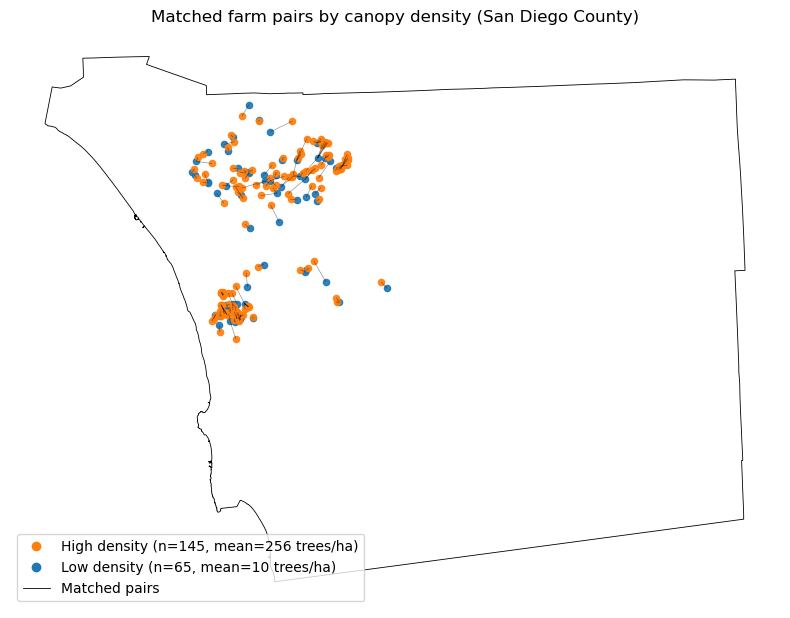

In [22]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

# ---- paths ----
parcels_path = Path(
    r"C:\Users\jbros\OneDrive\Documents\Bross_279_Match_Test"
    r"\Agricultural_Commodity_2020_shapefile\farm_parcels_merged.shp"
)
county_kml = Path(
    r"C:\Users\jbros\OneDrive\Documents\Bross_279_Match_Test\San_Diego_County_Boundary.kml"
)
matches_path = Path(
    r"C:\Users\jbros\OneDrive\Documents\Bross_279_Match_Test"
    r"\Bross_279_nn_matches_top10_bottom20_coast5km.csv"
)
summary_path = Path(  # has trees_per_ha per site
    r"C:\Users\jbros\OneDrive\Documents\Bross_279_Match_Test\Bross_279_site_summary.csv"
)

CA_ALBERS = 3310  # common metric CRS

def find_site_id_col(df):
    candidates = ["site_id", "SITE_ID", "Site_ID", "siteid", "permit_num", "objectid", "OBJECTID"]
    for c in candidates:
        if c in df.columns:
            return c
    df["site_id"] = df.index.astype(str)
    return "site_id"

# ---- load geometries ----
parcels = gpd.read_file(parcels_path)
site_col = find_site_id_col(parcels)
parcels = parcels.rename(columns={site_col: "site_id"})
parcels["site_id"] = parcels["site_id"].astype(str)

county = gpd.read_file(county_kml, driver="KML")

# project to common CRS
parcels = parcels.to_crs(CA_ALBERS)
county = county.to_crs(CA_ALBERS)

# dissolve to one geometry per site and get centroids
parcels_diss = parcels[["site_id", "geometry"]].dissolve(by="site_id", as_index=False)
parcels_pts = parcels_diss.copy()
parcels_pts["geometry"] = parcels_pts.geometry.centroid
parcels_pts = gpd.GeoDataFrame(parcels_pts, geometry="geometry", crs=f"EPSG:{CA_ALBERS}")

# ---- load attributes ----
matches = pd.read_csv(matches_path, dtype={"site_id_high": str, "site_id_low": str})
summary = pd.read_csv(summary_path, dtype={"site_id": str})

# bring trees_per_ha into centroids
if "trees_per_ha" in summary.columns:
    parcels_pts = parcels_pts.merge(
        summary[["site_id", "trees_per_ha"]],
        on="site_id",
        how="left"
    )
else:
    parcels_pts["trees_per_ha"] = pd.NA

# high / low site sets
high_ids = matches["site_id_high"].unique()
low_ids  = matches["site_id_low"].unique()

high_pts = parcels_pts[parcels_pts["site_id"].isin(high_ids)].copy()
low_pts  = parcels_pts[parcels_pts["site_id"].isin(low_ids)].copy()

# ---- plot ----
fig, ax = plt.subplots(figsize=(8, 8))

# county outline
county.boundary.plot(ax=ax, color="black", linewidth=0.6)

# thin black lines for each pair
for row in matches.itertuples(index=False):
    hi = row.site_id_high
    lo = row.site_id_low
    g_hi = high_pts.loc[high_pts["site_id"] == hi, "geometry"]
    g_lo = low_pts.loc[low_pts["site_id"] == lo, "geometry"]
    if g_hi.empty or g_lo.empty:
        continue
    x1, y1 = g_hi.iloc[0].x, g_hi.iloc[0].y
    x2, y2 = g_lo.iloc[0].x, g_lo.iloc[0].y
    ax.plot([x1, x2], [y1, y2], color="black", linewidth=0.4, alpha=0.5)

# plot points
low_pts.plot(ax=ax, markersize=20, color="tab:blue", alpha=0.9)
high_pts.plot(ax=ax, markersize=20, color="tab:orange", alpha=0.9)

ax.set_axis_off()
ax.set_title("Matched farm pairs by canopy density (San Diego County)")

# legend: counts + mean trees/ha
n_high = len(high_pts)
n_low = len(low_pts)
mean_high = high_pts["trees_per_ha"].mean()
mean_low = low_pts["trees_per_ha"].mean()

high_label = f"High density (n={n_high}, mean={mean_high:.0f} trees/ha)"
low_label  = f"Low density (n={n_low}, mean={mean_low:.0f} trees/ha)"

handles = [
    Line2D([0], [0], marker="o", linestyle="none", color="tab:orange", label=high_label),
    Line2D([0], [0], marker="o", linestyle="none", color="tab:blue", label=low_label),
    Line2D([0], [0], color="black", linewidth=0.6, label="Matched pairs"),
]
ax.legend(handles=handles, loc="lower left", frameon=True)

plt.tight_layout()
plt.show()
